# 10. Small Multiples em Mapas Geográficos: Análise Espaço-Temporal da Vacinação contra Sarampo

**Disciplina:** Análise Visual de Dados — Mestrado UNESP  
**Tema:** Avaliação longitudinal e espaço-temporal da vacinação contra sarampo no Brasil (SI-PNI / RNDS / SINAN)  
**Técnica Central:** Small Multiples (Facetamento em Grades Cartográficas e Cartogramas Hexagonais)

---

## 1. Fundamentação Teórica: Small Multiples em Cartografia Estatística

Na literatura canônica de visualização de dados e percepção humana (**Edward Tufte**, **Tamara Munzner**, **Colin Ware**), a técnica de **Small Multiples** (múltiplos pequenos) é o padrão-ouro para a análise comparativa multivariada:

1. **Olhos sobre a Memória (*Eyes Over Memory*) — Edward Tufte**:
   * *O problema das animações:* Transições temporais animadas e controles deslizantes interativos sobrecarregam severamente a memória de trabalho visual (*working memory*). O observador é forçado a reter o estado de um instante anterior para tentar deduzir variações, sofrendo com a "cegueira à mudança" (*change blindness*).
   * *A solução por Small Multiples:* Ao dispor todas as fatias de tempo ou categorias lado a lado no mesmo campo de visão, a comparação torna-se puramente espacial (*macro/micro readings*), reduzindo a carga cognitiva e permitindo escaneamento ocular instantâneo.

2. **Escala Compartilhada e Fidelidade de Cor (*Fixed / Shared Colormap*) — Tamara Munzner**:
   * Para que múltiplos cartográficos sejam honestos, **todos os painéis de uma mesma matriz devem compartilhar estritamente os mesmos limites numéricos (`vmin`, `vmax`) e a mesma função de transferência de cor**.
   * O colormap relativo (onde cada mapa normaliza seu próprio min/max) gera ilusões visuais graves: uma variação modesta em um trimestre estável aparentaria o mesmo contraste de uma explosão epidêmica.

3. **Mitigação do Efeito Área (*Area Bias*) — Colin Ware**:
   * Em mapas coropléticos geográficos, a área territorial de um polígono atua como um canal visual dominante e não intencional na percepção pré-atentiva. Estados geograficamente extensos mas de baixa densidade (como Amazonas e Pará) dominam visualmente o mapa, enquanto unidades territoriais compactas porém hiperpopulosas ou com indicadores anômalos (como Distrito Federal, Sergipe, Rio de Janeiro e São Paulo) tornam-se quase invisíveis.
   * *A solução metodológica:* Complementar mapas geográficos contínuos com **Cartogramas de Grade Hexagonal Uniforme (*Hexagonal Tile Grid Maps*)**, onde cada uma das 27 UFs possui exatamente o mesmo tamanho e peso perceptual, preservando as relações de vizinhança e latitude/longitude relativas.

4. **Anotações Direcionadas (*Directed Annotations*)**:
   * Em painéis múltiplos densos, anotações textuais diretas nos pontos de ruptura e anomalias epidemiológicas (ex: *callouts* no pico de vacinação ou em desertos de retenção vacinal) ancoram a atenção do leitor e aceleram drasticamente a compreensão.

---

## 2. Matrizes Analíticas Implementadas

| Matriz | Dimensão / Faceta | Métrica Analítica | Escala & Tipo Cartográfico |
|---|---|---|---|
| **Matriz 1** | **Espaço × Tempo** (2025Q1 a 2026Q3 + Ago/26) | Ritmo de doses por 1.000 hab. e explosão de campanha | Grade 2×4 sequencial uniforme (`Blues`) com escala compartilhada |
| **Mitigação 1** | **Viés de Área** (Geográfico vs Hexagonal) | Taxa acumulada por 1.000 hab. | Painel 1×2 comparando Coroplético vs Cartograma Hexagonal |
| **Matriz 2** | **Completude e Abandono** (D1 × D2 × Coorte 1-4 anos) | D1 vs D2 por 1.000 hab. e % crianças com 2+ doses | Grade 2×2: Sequencial compartilhada (D1/D2) e Divergente (`RdYlBu`) |
| **Matriz 3** | **Demografia e Intencionalidade** (Rotina vs Bloqueio) | % de doses por 4 macrofaixas etárias (0-4, 5-19, 20-39, 40-59) | Grade 2×2 comparando intencionalidade pediátrica vs adulta |
| **Matriz 4** | **Qualidade da Informação** (Oportunidade no RNDS) | % de doses registradas com atraso > 30 dias (semestral) | Grade 2×2 sequencial (`Purples`) com evolução 2025-S1 a 2026-S2 |
| **Matriz 5** | **Insumos Farmacêuticos** (SCR vs SCRV) | % de uso da vacina Tetra viral (SCRV) sobre o total | Grade 1×2: Mapa coroplético e Cartograma Hexagonal detalhado |

## 1. Setup, Infraestrutura Cartográfica e Carga dos Dados

In [ ]:
import os
import tempfile
from pathlib import Path
import json

# Silencia aviso de cache de fontes do matplotlib no Windows
os.environ.setdefault("MPLCONFIGDIR", tempfile.gettempdir())

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mtick
from matplotlib.collections import PolyCollection
from matplotlib.patches import RegularPolygon
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# Paleta visual padronizada do projeto
# ------------------------------------------------------------------------------
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
RED = "#c2272d"
PURPLE = "#6a3d9a"
TEXT_PRIMARY, TEXT_SECONDARY, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEM_DADO = "#d9d8d0"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "text.color": TEXT_PRIMARY,
    "font.size": 10,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_SECONDARY,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ------------------------------------------------------------------------------
# Localização dinâmica de diretórios (compatível com notebooks/ e raiz do repo)
# ------------------------------------------------------------------------------
def resolver_caminho(caminho_rel):
    for base in [Path("."), Path(".."), Path("../..")]:
        cand = base / caminho_rel
        if cand.exists():
            return cand
    return Path(caminho_rel)

CAMINHO_POP = resolver_caminho("data/silver/ibge/populacao_municipios.csv")
CAMINHO_GOLD = resolver_caminho("data/gold/vacinacao")
CAMINHO_BRONZE_IBGE = resolver_caminho("data/bronze/ibge")
CAMINHO_GOLD_IBGE = resolver_caminho("data/gold/ibge")
CAMINHO_GEO = CAMINHO_GOLD_IBGE if (CAMINHO_GOLD_IBGE / "uf.json").exists() else CAMINHO_BRONZE_IBGE

print(f"Diretório GeoJSON: {CAMINHO_GEO}")
print(f"Diretório Gold Vacinação: {CAMINHO_GOLD}")
print(f"Arquivo População Silver: {CAMINHO_POP}")

Diretório GeoJSON: data\gold\ibge
Diretório Gold Vacinação: data\gold\vacinacao
Arquivo População Silver: data\silver\ibge\populacao_municipios.csv


### Funções Cartográficas Especializadas
Implementação leve para renderizar malhas do IBGE sem necessidade de `geopandas`, com suporte a:
1. `coropletico`: Mapas coropléticos contínuos e discretos com controle estrito de `Normalize`.
2. `cartograma_hexagonal`: Cartograma topológico regular onde cada uma das 27 UFs é um hexágono de peso idêntico.
3. `anotacao_direcionada`: Rótulos em destaque (*callouts*) para apontar anomalias analíticas.

In [ ]:
# ------------------------------------------------------------------------------
# Leitor leve de GeoJSON do IBGE (sem dependência de geopandas)
# ------------------------------------------------------------------------------
def ler_geojson(caminho, chave_len):
    features = json.loads(Path(caminho).read_text(encoding="utf-8"))["features"]
    codigos, verts, dono = [], [], []
    for i, f in enumerate(features):
        codigos.append(f["properties"]["codarea"][:chave_len])
        g = f["geometry"]
        aneis = [g["coordinates"][0]] if g["type"] == "Polygon" else [p[0] for p in g["coordinates"]]
        for anel in aneis:
            verts.append(np.asarray(anel))
            dono.append(i)
    return codigos, verts, np.array(dono)

def centroide(anel):
    x, y = anel[:, 0], anel[:, 1]
    a = x[:-1] * y[1:] - x[1:] * y[:-1]
    area = a.sum() / 2
    if abs(area) < 1e-12:
        return anel.mean(axis=0)
    return np.array([((x[:-1] + x[1:]) * a).sum(), ((y[:-1] + y[1:]) * a).sum()]) / (6 * area)

# Carrega metadados e geometrias de UFs
uf_meta = pd.DataFrame(json.loads((CAMINHO_GEO / "uf_meta.json").read_text(encoding="utf-8")))
ID_PARA_SIGLA = dict(zip(uf_meta["id"].astype(str), uf_meta["sigla"]))
SIGLA_PARA_ID = {v: k for k, v in ID_PARA_SIGLA.items()}
REGIAO = dict(zip(uf_meta["sigla"], uf_meta["regiao"].map(lambda r: r["nome"])))

cod_uf, verts_uf, dono_uf = ler_geojson(CAMINHO_GEO / "uf.json", 2)
sigla_uf = [ID_PARA_SIGLA[c] for c in cod_uf]
cent_uf = {s: centroide(max([v for v, d in zip(verts_uf, dono_uf) if d == i], key=len))
           for i, s in enumerate(sigla_uf)}

LIM_X, LIM_Y = (-74.2, -33.5), (-34.2, 5.6)
ASPECTO = 1 / np.cos(np.radians(-15))

def base_mapa(ax, contorno_uf=True, cor_uf="white", lw=0.6):
    ax.set_xlim(*LIM_X)
    ax.set_ylim(*LIM_Y)
    ax.set_aspect(ASPECTO)
    ax.axis("off")
    if contorno_uf:
        ax.add_collection(PolyCollection(verts_uf, facecolors="none", edgecolors=cor_uf, linewidths=lw, zorder=3))

def coropletico(ax, valores, norm=None, cmap="Blues", bins=None, extremos="neither",
                titulo=None, rotulo=None, colorbar=True, fmt="{:,.0f}", cbar_kw=None):
    """Renderiza mapa coroplético de UFs com controle estrito de normalização de cores."""
    v = np.array([valores.get(c, np.nan) for c in sigla_uf], dtype=float)[dono_uf]
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad(SEM_DADO)
    if norm is None:
        if bins is not None:
            norm = mcolors.BoundaryNorm(bins, cm.N, extend=extremos)
        else:
            val_validos = v[~np.isnan(v)]
            vmin = val_validos.min() if len(val_validos) > 0 else 0
            vmax = val_validos.max() if len(val_validos) > 0 else 1
            norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
            
    pc = PolyCollection(verts_uf, array=np.ma.masked_invalid(v), cmap=cm, norm=norm,
                        edgecolors="white", linewidths=0.5, zorder=1)
    ax.add_collection(pc)
    base_mapa(ax, contorno_uf=False)
    if titulo:
        ax.set_title(titulo, loc="left", fontweight="bold", fontsize=11)
    if colorbar:
        kw = dict(shrink=0.55, pad=0.01, aspect=22)
        kw.update(cbar_kw or {})
        cb = plt.colorbar(pc, ax=ax, **kw)
        cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: fmt.format(x).replace(",", ".")))
        if rotulo:
            cb.set_label(rotulo)
    return pc

# ------------------------------------------------------------------------------
# Coordenadas do Cartograma Hexagonal do Brasil (27 UFs regulares)
# ------------------------------------------------------------------------------
HEX_COORDS = {
    # Norte (7)
    'RR': (2, 7), 'AP': (6, 7),
    'AM': (1, 6), 'PA': (4, 6), 'TO': (5, 5), 'RO': (2, 5), 'AC': (0, 5),
    # Nordeste (9)
    'MA': (6, 6), 'PI': (6, 5), 'CE': (7, 6), 'RN': (8, 6), 'PB': (8, 5), 'PE': (8, 4), 'AL': (8, 3), 'SE': (7, 3), 'BA': (6, 4),
    # Centro-Oeste (4)
    'MT': (3, 5), 'GO': (4, 4), 'DF': (5, 4), 'MS': (3, 3),
    # Sudeste (4)
    'MG': (5, 3), 'ES': (6, 3), 'RJ': (5, 2), 'SP': (4, 2),
    # Sul (3)
    'PR': (4, 1), 'SC': (4, 0), 'RS': (4, -1),
}

def cartograma_hexagonal(ax, valores, norm=None, cmap="Blues", titulo=None, fmt="{:.0f}",
                        mostrar_valores=True, tamanho_sigla=8, tamanho_val=6.5):
    """Desenha um cartograma de grade hexagonal uniforme de 27 UFs para neutralizar o viés de área."""
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad(SEM_DADO)
    val_series = pd.Series(valores).dropna()
    if norm is None:
        norm = mcolors.Normalize(vmin=val_series.min(), vmax=val_series.max())
    
    for uf, (x, y) in HEX_COORDS.items():
        val = valores.get(uf, np.nan)
        if np.isnan(val):
            fc = SEM_DADO
            cor_texto = TEXT_SECONDARY
        else:
            fc = cm(norm(val))
            # Cálculo de luminância para contraste ideal do texto
            lum = 0.299 * fc[0] + 0.587 * fc[1] + 0.114 * fc[2]
            cor_texto = "white" if lum < 0.55 else TEXT_PRIMARY
            
        p = RegularPolygon((x, y), numVertices=6, radius=0.52, orientation=np.radians(30),
                           facecolor=fc, edgecolor="white", lw=1.3, zorder=2)
        ax.add_patch(p)
        if mostrar_valores and not np.isnan(val):
            ax.text(x, y + 0.10, uf, ha="center", va="center", color=cor_texto, fontweight="bold", fontsize=tamanho_sigla, zorder=3)
            ax.text(x, y - 0.16, fmt.format(val), ha="center", va="center", color=cor_texto, fontsize=tamanho_val, zorder=3)
        else:
            ax.text(x, y, uf, ha="center", va="center", color=cor_texto, fontweight="bold", fontsize=tamanho_sigla, zorder=3)
            
    ax.set_xlim(-1, 9.5)
    ax.set_ylim(-2, 8.2)
    ax.set_aspect("equal")
    ax.axis("off")
    if titulo:
        ax.set_title(titulo, loc="left", fontweight="bold", fontsize=11)

def anotacao_direcionada(ax, sigla, texto, xytext=(18, 18), cor=RED, fontsize=8.5, lw=1.2):
    """Anota anomalias epidemiológicas diretamente no centroide geográfico da UF."""
    if sigla in cent_uf:
        x, y = cent_uf[sigla]
        ax.annotate(texto, xy=(x, y), xytext=xytext, textcoords="offset points",
                    fontsize=fontsize, fontweight="bold", color=cor,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=cor, alpha=0.92, lw=0.8),
                    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2", color=cor, lw=lw),
                    zorder=10)

### Carregamento das Tabelas Silver e Gold

In [ ]:
# 1. Denominador Populacional por Município (Silver)
pop = pd.read_csv(CAMINHO_POP, dtype={"codigo_municipio": str})
pop["uf"] = pop["codigo_municipio"].str[:2].map(ID_PARA_SIGLA)
pop_uf = pop.groupby("uf")["populacao"].sum()

# 2. Tabelas Analíticas Gold
uf_mes = pd.read_parquet(CAMINHO_GOLD / "gold_doses_uf_mes.parquet")
coorte = pd.read_parquet(CAMINHO_GOLD / "gold_coorte_criancas_municipio.parquet")
perfil = pd.read_parquet(CAMINHO_GOLD / "gold_perfil.parquet")
atraso = pd.read_parquet(CAMINHO_GOLD / "gold_atraso_registro.parquet")

periodo = f"{uf_mes['ano_mes'].min()} a {uf_mes['ano_mes'].max()}"
total_doses = uf_mes["doses"].sum()
pop_total = pop_uf.sum()

print(f"Período temporal: {periodo}")
print(f"Total de doses analisadas: {total_doses:,} doses")
print(f"População total do Brasil (denominador IBGE 2026): {pop_total:,} habitantes")

Período temporal: 2025-01 a 2026-09
Total de doses analisadas: 16,670,125 doses
População total do Brasil (denominador IBGE 2026): 214,211,951 habitantes


## 2. Recomendação Crítica 1: Evitando o Viés do "Mapa de População"

> [!WARNING]
> **A Falácia Cartográfica Clássica:** Mapas de contagens absolutas de eventos humanos invariavelmente refletem apenas a densidade demográfica do território (o famoso "mapa de onde as pessoas vivem", criticado por Munzner e Ware).

Abaixo, demonstramos a diferença fundamental entre:
1. **Doses Absolutas:** Dominado completamente por São Paulo (mais de 5,2 milhões de doses) e Minas Gerais.
2. **Taxa por 1.000 Habitantes:** Normalizado pela população do IBGE (`populacao_municipios.csv`), revelando o **esforço relativo real** de vacinação.

Top 5 UFs em Taxa Relativa (Doses/1.000 hab.):
uf_paciente
RR    233.6
AC    129.4
SP    112.9
AM    109.2
MT     92.2

Top 5 UFs em Volume Absoluto:
uf_paciente
SP    5,211,461
MG    1,137,310
BA      860,202
RJ      854,164
PR      769,508


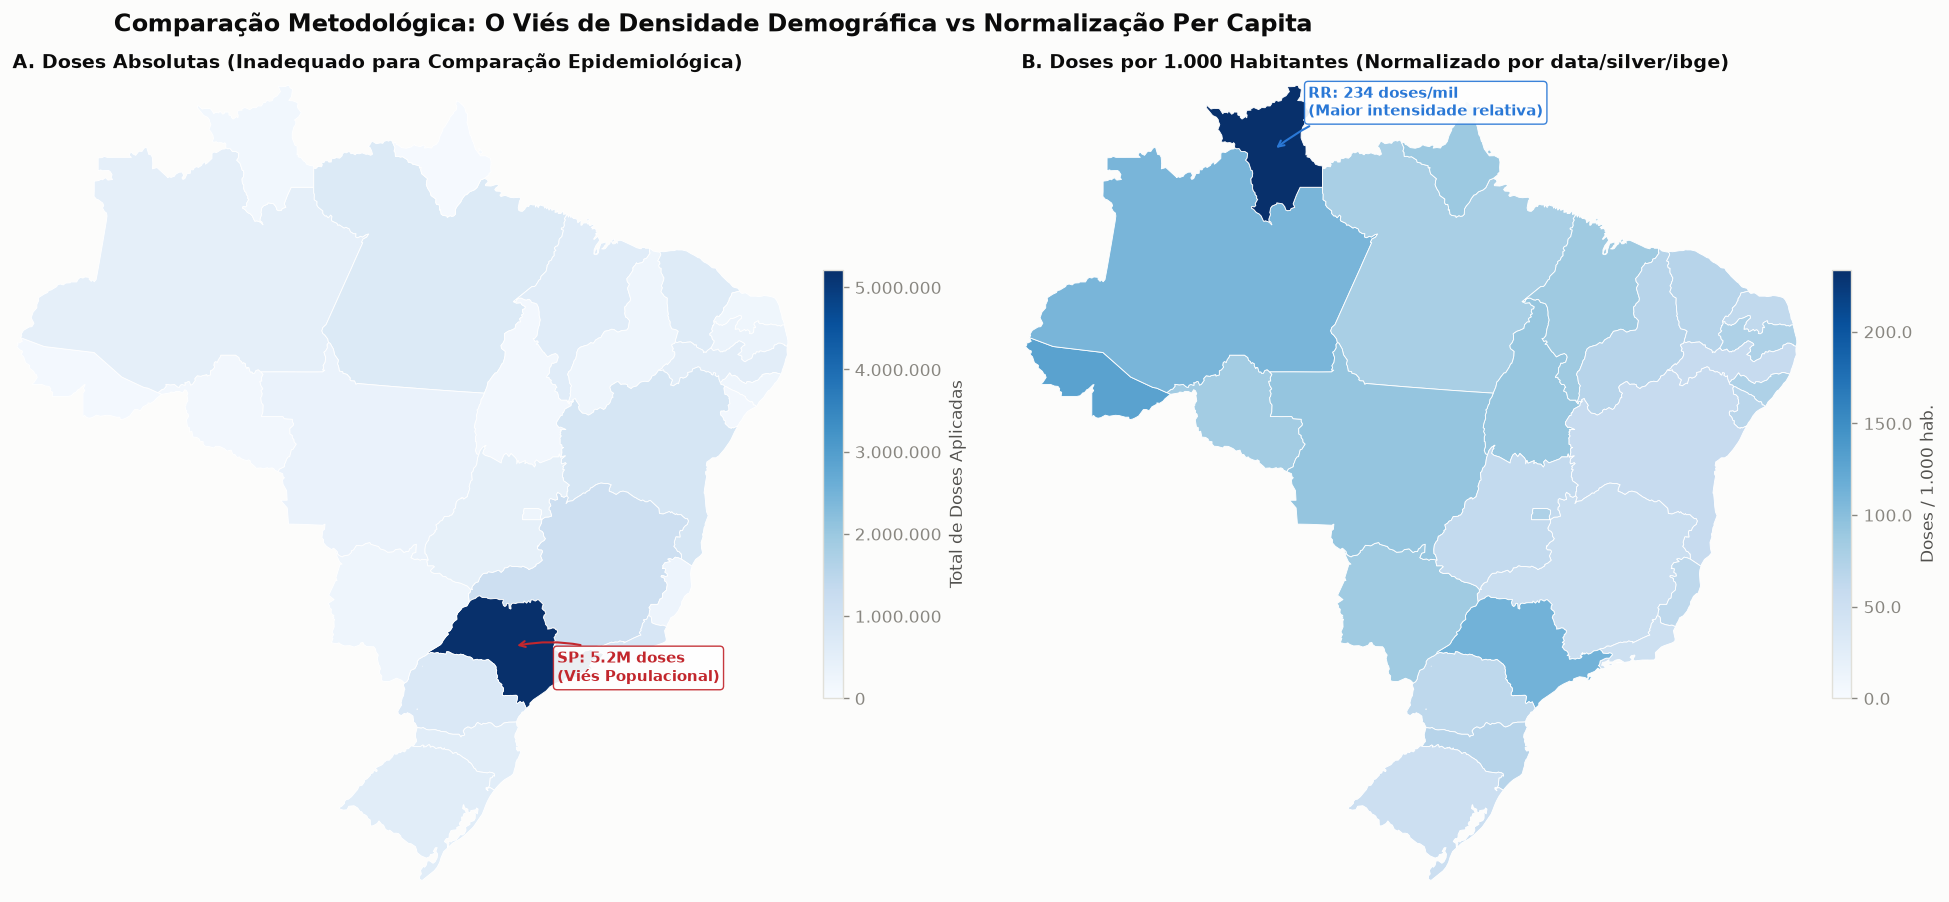

In [ ]:
# Agregação geral por UF
doses_totais_uf = uf_mes[uf_mes["uf_paciente"].isin(sigla_uf)].groupby("uf_paciente")["doses"].sum()
taxa_geral_uf = (doses_totais_uf / pop_uf * 1000).dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

# Painel 1: Contagem Absoluta (Viés Demográfico)
norm_abs = mcolors.Normalize(vmin=0, vmax=doses_totais_uf.max())
coropletico(axes[0], doses_totais_uf.to_dict(), norm=norm_abs, cmap="Blues",
            titulo="A. Doses Absolutas (Inadequado para Comparação Epidemiológica)",
            rotulo="Total de Doses Aplicadas", fmt="{:,.0f}", cbar_kw={"shrink": 0.5})
anotacao_direcionada(axes[0], "SP", f"SP: {doses_totais_uf['SP'] / 1e6:.1f}M doses\n(Viés Populacional)",
                     xytext=(25, -20), cor=RED)

# Painel 2: Taxa por 1.000 Habitantes (Comparação Justa)
norm_taxa = mcolors.Normalize(vmin=0, vmax=taxa_geral_uf.max())
coropletico(axes[1], taxa_geral_uf.to_dict(), norm=norm_taxa, cmap="Blues",
            titulo="B. Doses por 1.000 Habitantes (Normalizado por data/silver/ibge)",
            rotulo="Doses / 1.000 hab.", fmt="{:,.1f}", cbar_kw={"shrink": 0.5})
anotacao_direcionada(axes[1], "RR", f"RR: {taxa_geral_uf['RR']:.0f} doses/mil\n(Maior intensidade relativa)",
                     xytext=(20, 20), cor=BLUE)

fig.suptitle("Comparação Metodológica: O Viés de Densidade Demográfica vs Normalização Per Capita",
             x=0.06, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

print("Top 5 UFs em Taxa Relativa (Doses/1.000 hab.):")
print(taxa_geral_uf.nlargest(5).round(1).to_string())
print("\nTop 5 UFs em Volume Absoluto:")
print(doses_totais_uf.nlargest(5).map("{:,.0f}".format).to_string())

## 3. Matriz 1: Small Multiples Espaço × Tempo — A Megacampanha de Agosto/2026

### Constatação dos Dados
* Durante 2025 e o primeiro semestre de 2026, o ritmo nacional de vacinação contra sarampo permaneceu estável em torno de **600 mil a 800 mil doses/mês**, com cerca de 95% das doses destinadas à rotina do calendário infantil.
* **A Explosão de Agosto/2026:** Em agosto de 2026, o volume nacional explodiu para **3.297.683 doses**, e a proporção de rotina desabou para **47,79%**, caracterizando uma megacampanha nacional e ações massivas de bloqueio vacinal.
* **Assimetria Espacial Severa:** O estado de **São Paulo multiplicou seu volume mensal em 19,4 vezes em relação à sua média de 2025** (saltando de ~126 mil doses/mês para 2.460.817 doses em um único mês). Em contraste, a maioria dos estados do Nordeste cresceu entre apenas 1,5x e 2,0x.

### Decisão de Visualização (Small Multiples 2×4)
* **Estrutura:** Grade de **2×4 mapas coropléticos** cobrindo os 7 trimestres disponíveis (`2025Q1` a `2026Q3`) mais o mapa comparativo de **Agosto/2026**.
* **Escala Compartilhada Obrigatória:** Todos os 8 painéis utilizam exatamente o mesmo colormap `Blues` e a mesma escala `Normalize(vmin=0, vmax=65)` (definida pelo percentil 98 das taxas trimestrais).
* **Benefício Cognitivo (*Eyes Over Memory*):** O leitor detecta instantaneamente a "ignição" repentina do Sudeste no 3º trimestre de 2026 e o foco absoluto em São Paulo no mês de pico, sem precisar memorizar quadros anteriores.

São Paulo em Agosto/2026: 2,460,817 doses vs Média mensal em 2025: 126,630 doses (Fator de multiplicação: 19.4x)


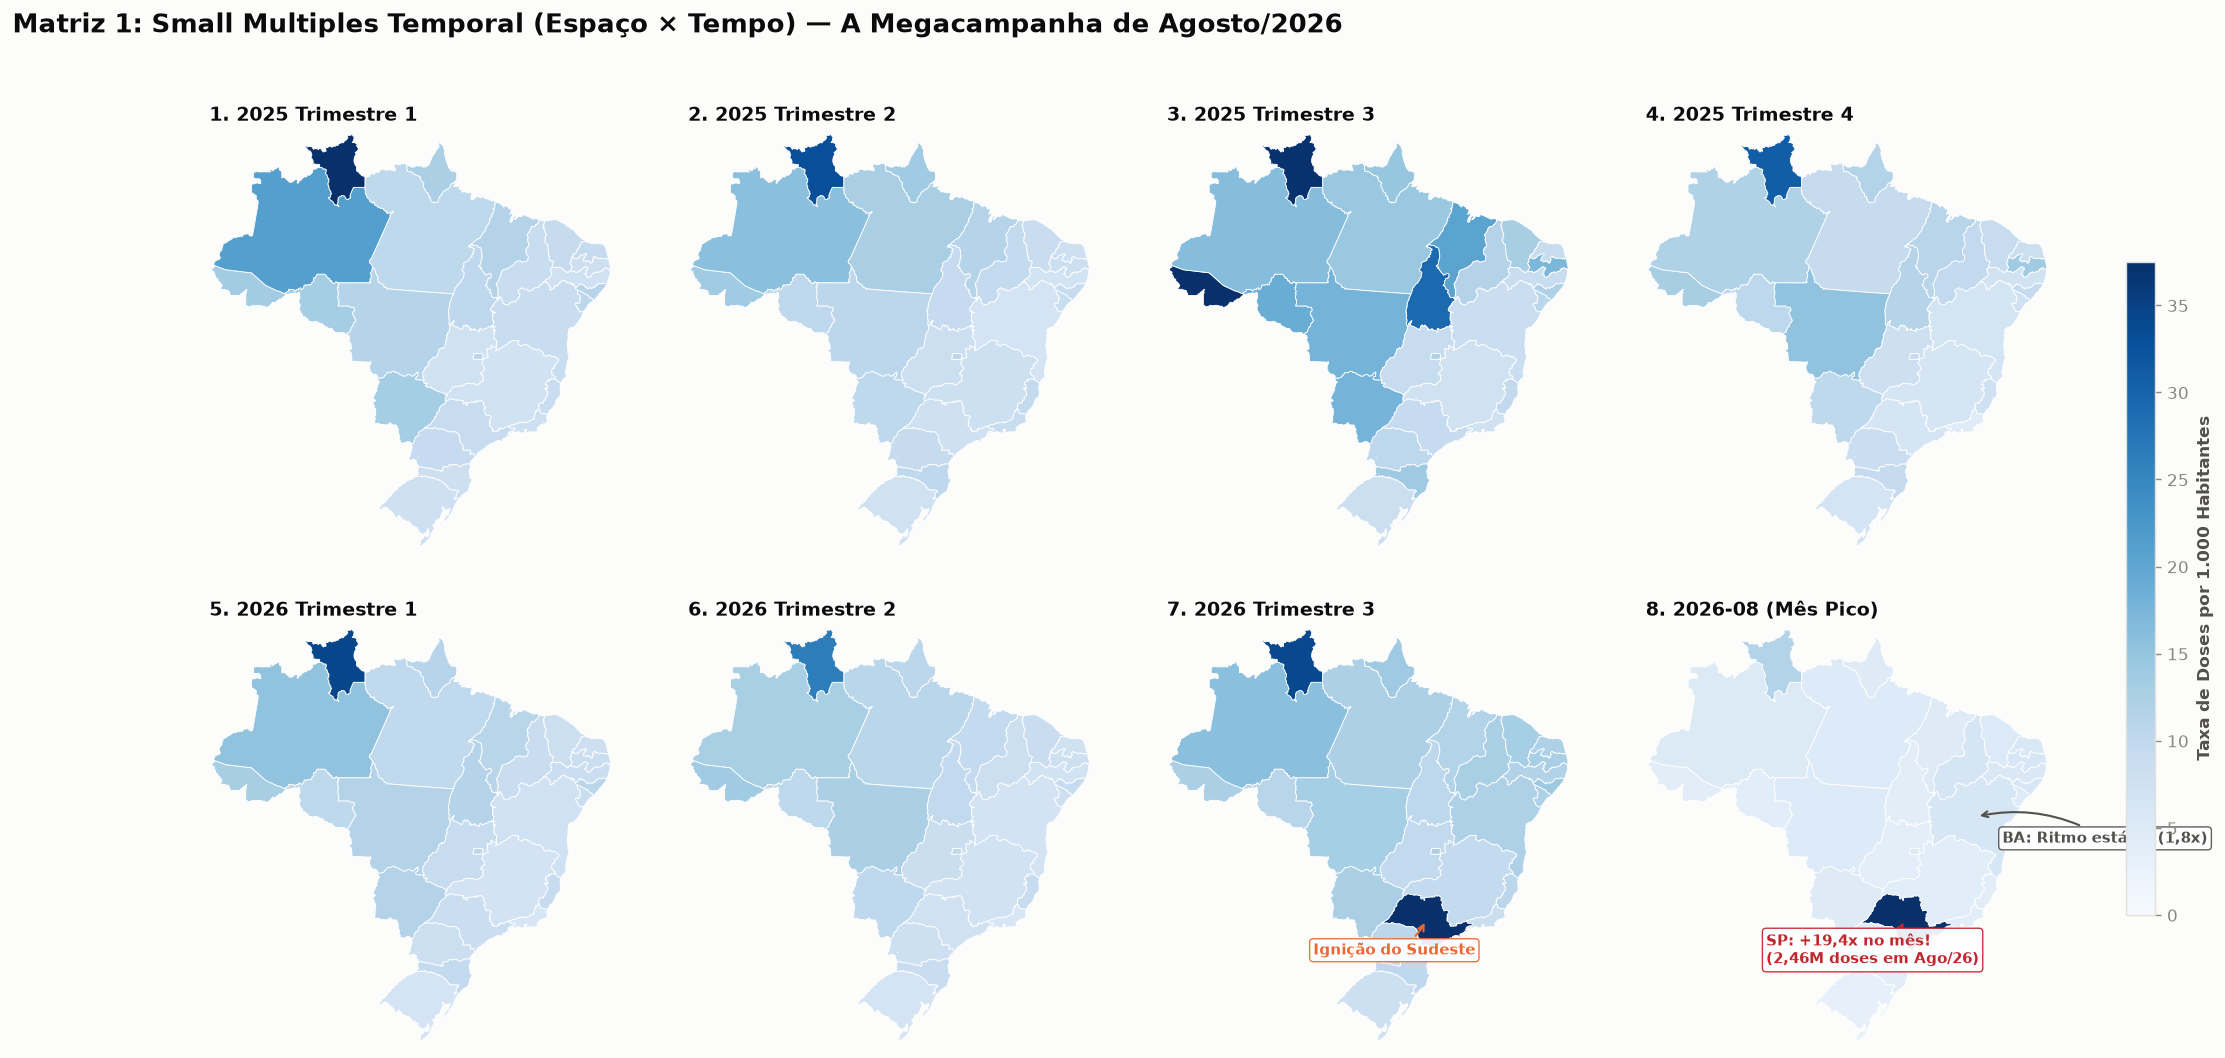

In [ ]:
# Agrupa doses por trimestre e calcula taxa trimestral por 1.000 hab.
uf_mes["tri"] = pd.PeriodIndex(uf_mes["ano_mes"], freq="M").asfreq("Q").astype(str)
tri_uf = uf_mes[uf_mes["uf_paciente"].isin(sigla_uf)].groupby(["tri", "uf_paciente"])["doses"].sum().unstack(0)
taxa_tri = tri_uf.div(pop_uf.reindex(tri_uf.index), axis=0) * 1000

# Taxa de Agosto/2026 (mês da megacampanha)
ago26 = uf_mes[(uf_mes["ano_mes"] == "2026-08") & (uf_mes["uf_paciente"].isin(sigla_uf))].groupby("uf_paciente")["doses"].sum()
taxa_ago26 = (ago26 / pop_uf * 1000).rename("2026-08 (Mês Pico)")

# Lista consolidada de 8 múltiplos
colunas_painel = list(taxa_tri.columns) + ["2026-08 (Mês Pico)"]
dados_paineis = {c: taxa_tri[c].to_dict() for c in taxa_tri.columns}
dados_paineis["2026-08 (Mês Pico)"] = taxa_ago26.to_dict()

# Escala compartilhada estrita (Shared Colormap)
v_todos = np.concatenate([taxa_tri.values.ravel(), taxa_ago26.values])
vmin, vmax = 0, np.nanpercentile(v_todos, 98.5)
norm_tempo = mcolors.Normalize(vmin=vmin, vmax=vmax)
cmap_tempo = plt.get_cmap("Blues")

fig, axes = plt.subplots(2, 4, figsize=(19, 9.5))
axes = axes.ravel()

for i, chave in enumerate(colunas_painel):
    ax = axes[i]
    titulo_formatado = chave.replace("Q", " Trimestre ") if "Q" in chave else chave
    coropletico(ax, dados_paineis[chave], norm=norm_tempo, cmap=cmap_tempo, colorbar=False,
                titulo=f"{i+1}. {titulo_formatado}")
    
    # Anotações direcionadas no painel do pico de campanha
    if chave == "2026-08 (Mês Pico)":
        anotacao_direcionada(ax, "SP", "SP: +19,4x no mês!\n(2,46M doses em Ago/26)", xytext=(-80, -25), cor=RED)
        anotacao_direcionada(ax, "BA", "BA: Ritmo estável (1,8x)", xytext=(15, -15), cor=TEXT_SECONDARY)
    elif chave == "2026Q3":
        anotacao_direcionada(ax, "SP", "Ignição do Sudeste", xytext=(-65, -20), cor=ORANGE)

# Barra de cores compartilhada única (Shared Colorbar)
fig.subplots_adjust(right=0.92, hspace=0.18, wspace=0.06)
cax = fig.add_axes([0.94, 0.22, 0.012, 0.55])
sm = plt.cm.ScalarMappable(cmap=cmap_tempo, norm=norm_tempo)
cb = fig.colorbar(sm, cax=cax)
cb.set_label("Taxa de Doses por 1.000 Habitantes", fontsize=10, fontweight="bold")
cb.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}"))

fig.suptitle("Matriz 1: Small Multiples Temporal (Espaço × Tempo) — A Megacampanha de Agosto/2026",
             x=0.05, ha="left", fontweight="bold", fontsize=15)
plt.show()

# Análise numérica de apoio
sp_ago = ago26.get("SP", 0)
sp_media_2025 = uf_mes[(uf_mes["uf_paciente"] == "SP") & (uf_mes["ano_mes"].str.startswith("2025"))].groupby("ano_mes")["doses"].sum().mean()
print(f"São Paulo em Agosto/2026: {sp_ago:,} doses vs Média mensal em 2025: {sp_media_2025:,.0f} doses (Fator de multiplicação: {sp_ago/sp_media_2025:.1f}x)")

## 4. Recomendação Crítica 2: Mitigando o Efeito Área com Cartograma Hexagonal

> [!NOTE]
> **Fundamentação de Colin Ware (*Area Disparity*):** No mapa coroplético tradicional do Brasil, a Região Norte ocupa **mais de 45% da superfície visual**, conferindo um peso visual desproporcional a estados como Amazonas e Pará. Em contrapartida, unidades federativas pequenas mas densas e estratégicas (como Distrito Federal, Sergipe, Espírito Santo e Rio de Janeiro) tornam-se praticamente imperceptíveis.

Abaixo, apresentamos uma visualização comparativa direta:
* **Esquerda:** Mapa Coroplético Geográfico Tradicional.
* **Direita:** **Cartograma de Grade Hexagonal Uniforme**, onde cada UF recebe **exatamente 1 hexágono regular de área igual**, equalizando o peso cognitivo de cada unidade da federação.

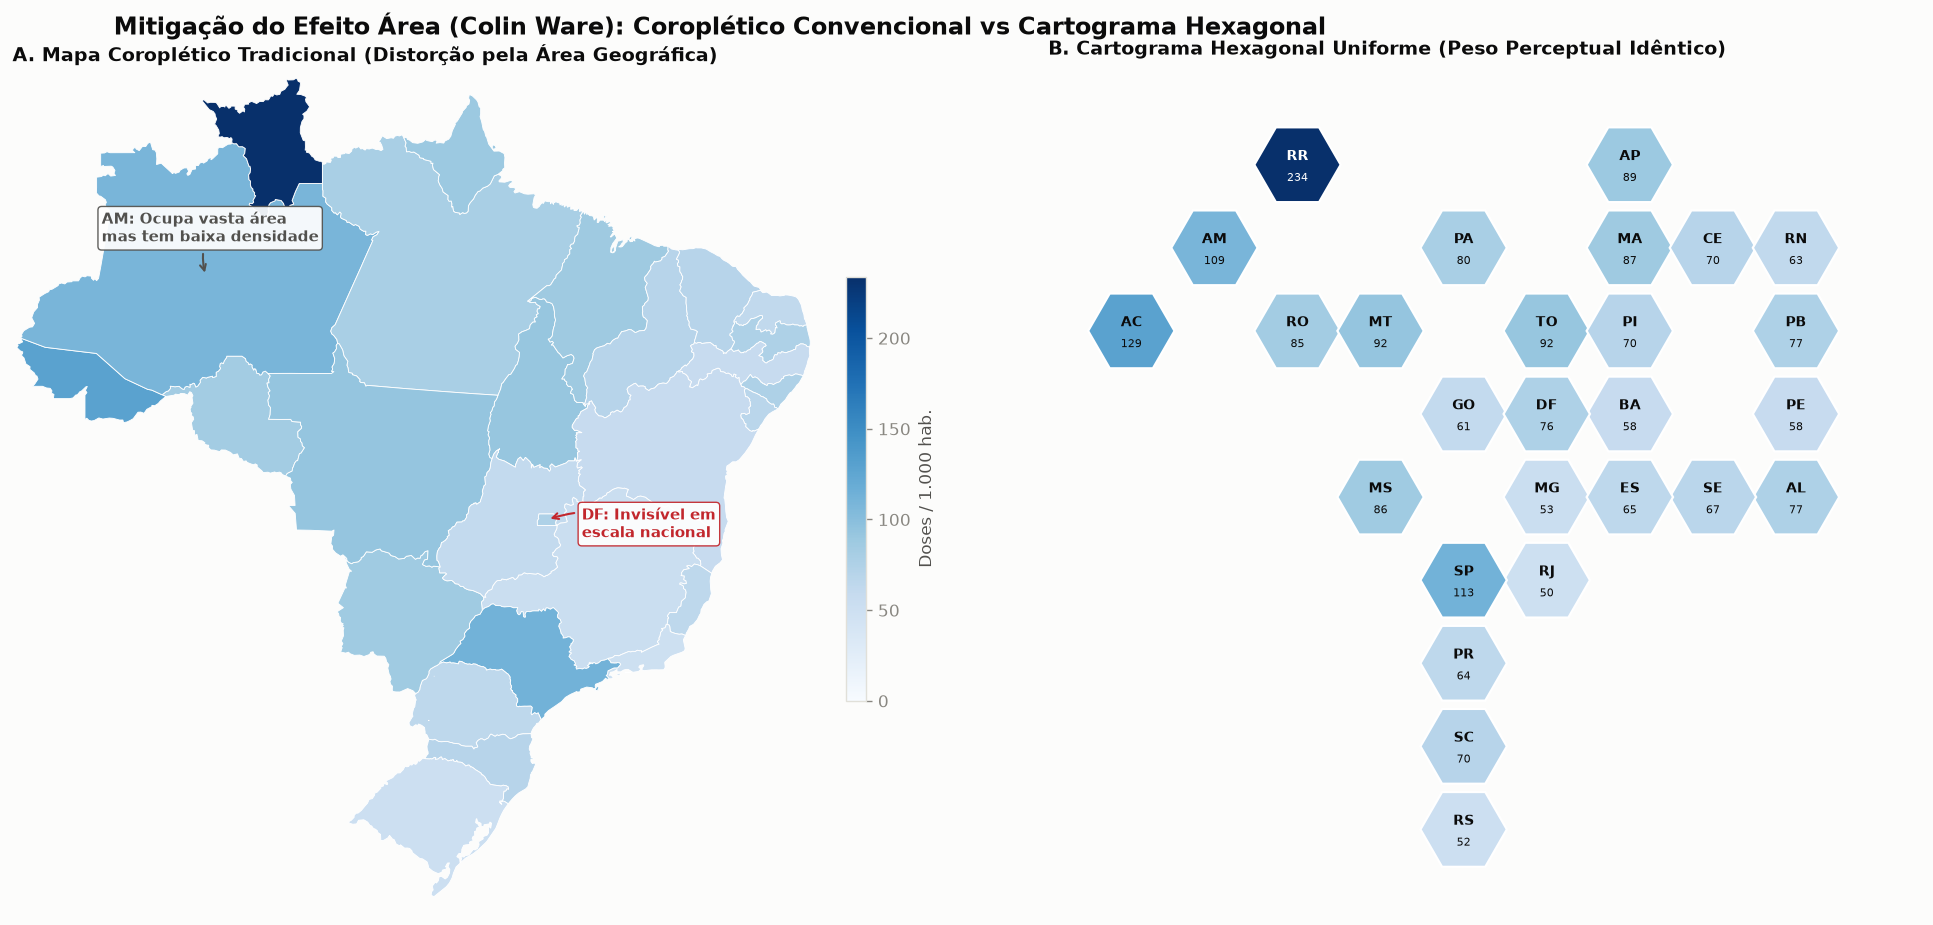

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

# Mapa Coroplético Geográfico
coropletico(axes[0], taxa_geral_uf.to_dict(), norm=norm_taxa, cmap="Blues",
            titulo="A. Mapa Coroplético Tradicional (Distorção pela Área Geográfica)",
            rotulo="Doses / 1.000 hab.", fmt="{:,.0f}", cbar_kw={"shrink": 0.5})
anotacao_direcionada(axes[0], "AM", "AM: Ocupa vasta área\nmas tem baixa densidade", xytext=(-60, 20), cor=TEXT_SECONDARY)
anotacao_direcionada(axes[0], "DF", "DF: Invisível em\nescala nacional", xytext=(20, -10), cor=RED)

# Cartograma Hexagonal Uniforme (Mitigação do Efeito Área)
cartograma_hexagonal(axes[1], taxa_geral_uf.to_dict(), norm=norm_taxa, cmap="Blues",
                     titulo="B. Cartograma Hexagonal Uniforme (Peso Perceptual Idêntico)",
                     fmt="{:.0f}")

fig.suptitle("Mitigação do Efeito Área (Colin Ware): Coroplético Convencional vs Cartograma Hexagonal",
             x=0.06, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## 5. Matriz 2: Efetividade do Esquema e Abandono (D1 × D2 × Coorte 1–4 Anos)

### Constatação dos Dados
O calendário básico preconiza a 1ª dose da tríplice viral (D1) aos 12 meses e a 2ª dose (D2/SCRV) aos 15 meses.
* A análise longitudinal da tabela `gold_coorte_criancas_municipio.parquet` revela um **forte abismo regional na retenção da 2ª dose**:
  * **Altas taxas de completude vacinal:** Minas Gerais (59,6%), Ceará (57,1%), Espírito Santo (56,4%) e Alagoas (56,1%).
  * **Desertos de completude vacinal:** Roraima (38,3%), Acre (42,4%), Amapá (42,8%) e Pará (43,5%).

### Decisão de Visualização (Grade 2×2)
* **Painel A (D1 por 1.000 hab.):** Mede a porta de entrada da população infantil no sistema.
* **Painel B (D2 por 1.000 hab.):** Compartilha **estritamente a mesma escala de D1**, demonstrando visualmente o degrau de deserção.
* **Painel C (% Coorte 1-4 anos com 2+ doses):** Utiliza **escala divergente (`RdYlBu`)** centrada na mediana nacional (~51%), destacando em tons quentes os desertos de completude e em tons azuis os polos de retenção.
* **Painel D (Cartograma Hexagonal da Coorte):** Exibe os percentuais exatos em cada federação com igual peso visual.

Estados com Maior Completude (2+ doses em crianças 1-4 anos):
uf_paciente
MG    59.6%
CE    57.1%
ES    56.4%
AL    56.1%

Estados com Menor Completude (Desertos Vacinais):
uf_paciente
RR    38.3%
AC    42.4%
AP    42.8%
PA    43.5%


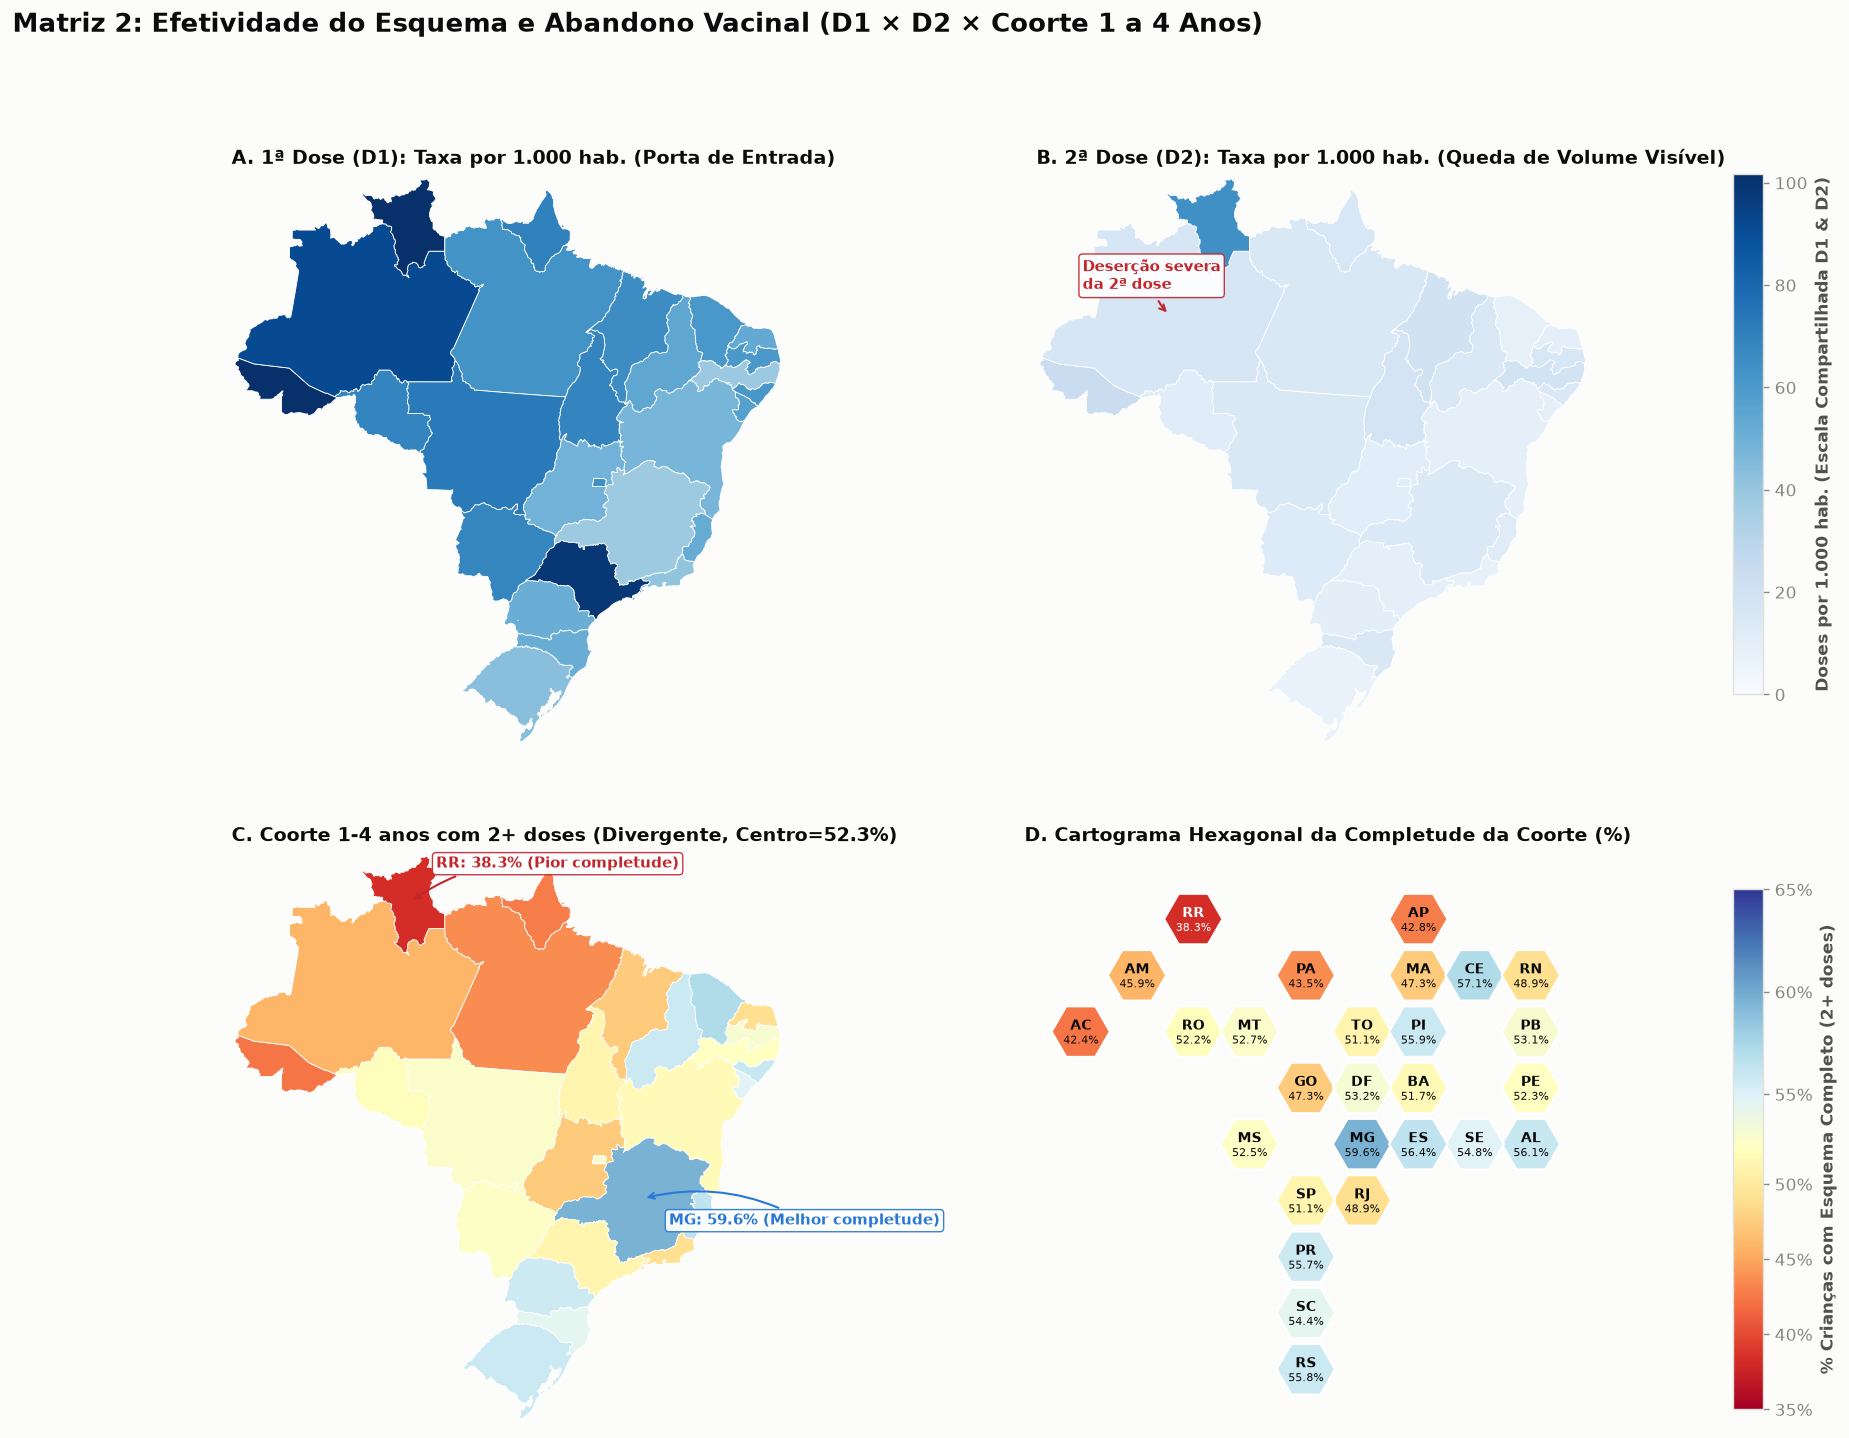

In [ ]:
# Calcula taxas de D1 e D2 por 1.000 hab.
d1_uf = uf_mes[uf_mes["dose_grupo"] == "1ª dose"].groupby("uf_paciente")["doses"].sum()
d2_uf = uf_mes[uf_mes["dose_grupo"] == "2ª dose"].groupby("uf_paciente")["doses"].sum()
taxa_d1 = (d1_uf / pop_uf * 1000).dropna().loc[lambda x: x.index.isin(sigla_uf)]
taxa_d2 = (d2_uf / pop_uf * 1000).dropna().loc[lambda x: x.index.isin(sigla_uf)]

# Agregação da Coorte de Crianças de 1 a 4 anos (Gold)
coorte_uf = coorte.groupby("uf_paciente")[["criancas_vacinadas", "criancas_com_2_ou_mais_doses"]].sum()
pct_coorte = (coorte_uf["criancas_com_2_ou_mais_doses"] / coorte_uf["criancas_vacinadas"] * 100).loc[lambda x: x.index.isin(sigla_uf)]

# 1. Escala compartilhada estrita para D1 e D2
vmax_d1d2 = max(taxa_d1.quantile(0.95), taxa_d2.quantile(0.95))
norm_d1d2 = mcolors.Normalize(vmin=0, vmax=vmax_d1d2)

# 2. Escala divergente centrada na mediana nacional da coorte
mediana_coorte = pct_coorte.median()
norm_div = mcolors.TwoSlopeNorm(vcenter=mediana_coorte, vmin=35, vmax=65)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# Painel A: 1ª Dose (Porta de Entrada)
coropletico(axes[0, 0], taxa_d1.to_dict(), norm=norm_d1d2, cmap="Blues", colorbar=False,
            titulo="A. 1ª Dose (D1): Taxa por 1.000 hab. (Porta de Entrada)")

# Painel B: 2ª Dose (Fechamento de Esquema)
coropletico(axes[0, 1], taxa_d2.to_dict(), norm=norm_d1d2, cmap="Blues", colorbar=False,
            titulo="B. 2ª Dose (D2): Taxa por 1.000 hab. (Queda de Volume Visível)")
anotacao_direcionada(axes[0, 1], "AM", "Deserção severa\nda 2ª dose", xytext=(-50, 15), cor=RED)

# Painel C: % Coorte 1 a 4 anos com 2+ doses (Divergente)
coropletico(axes[1, 0], pct_coorte.to_dict(), norm=norm_div, cmap="RdYlBu", colorbar=False,
            titulo=f"C. Coorte 1-4 anos com 2+ doses (Divergente, Centro={mediana_coorte:.1f}%)")
anotacao_direcionada(axes[1, 0], "RR", f"RR: {pct_coorte['RR']:.1f}% (Pior completude)", xytext=(15, 20), cor=RED)
anotacao_direcionada(axes[1, 0], "MG", f"MG: {pct_coorte['MG']:.1f}% (Melhor completude)", xytext=(15, -15), cor=BLUE)

# Painel D: Cartograma Hexagonal da Coorte de Crianças
cartograma_hexagonal(axes[1, 1], pct_coorte.to_dict(), norm=norm_div, cmap="RdYlBu",
                     titulo="D. Cartograma Hexagonal da Completude da Coorte (%)", fmt="{:.1f}%")

# Ajuste fino de subplots e barras compartilhadas
fig.subplots_adjust(right=0.90, hspace=0.18, wspace=0.08)

# Barra compartilhada linha superior (D1 e D2)
cax_top = fig.add_axes([0.92, 0.56, 0.015, 0.32])
sm_top = plt.cm.ScalarMappable(cmap="Blues", norm=norm_d1d2)
cb_top = fig.colorbar(sm_top, cax=cax_top)
cb_top.set_label("Doses por 1.000 hab. (Escala Compartilhada D1 & D2)", fontsize=9.5, fontweight="bold")

# Barra compartilhada linha inferior (Coorte 1-4 anos)
cax_bot = fig.add_axes([0.92, 0.12, 0.015, 0.32])
sm_bot = plt.cm.ScalarMappable(cmap="RdYlBu", norm=norm_div)
cb_bot = fig.colorbar(sm_bot, cax=cax_bot)
cb_bot.set_label("% Crianças com Esquema Completo (2+ doses)", fontsize=9.5, fontweight="bold")
cb_bot.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}%"))

fig.suptitle("Matriz 2: Efetividade do Esquema e Abandono Vacinal (D1 × D2 × Coorte 1 a 4 Anos)",
             x=0.06, ha="left", fontweight="bold", fontsize=15)
plt.show()

print("Estados com Maior Completude (2+ doses em crianças 1-4 anos):")
print(pct_coorte.nlargest(4).round(1).map("{:.1f}%".format).to_string())
print("\nEstados com Menor Completude (Desertos Vacinais):")
print(pct_coorte.nsmallest(4).round(1).map("{:.1f}%".format).to_string())

## 6. Matriz 3: Demografia e Intencionalidade (Crianças de Rotina × Adultos em Bloqueio)

### Constatação dos Dados
* O Programa Nacional de Imunizações (PNI) destina a vacina contra sarampo primordialmente a lactentes aos 12 e 15 meses.
* Contudo, na tabela `gold_perfil.parquet`, a distribuição etária revela perfis epidemiológicos drasticamente opostos entre federações:
  * **Polos de Bloqueio e Campanhas Adultas:** Em **Roraima (47,5%)**, **São Paulo (46,0%)** e **Distrito Federal (43,1%)**, quase metade de todas as doses aplicadas destinaram-se a adultos de 20 a 59 anos (migração em RR, rastreamento urbano de surtos e campanhas ocupacionais em SP e DF).
  * **Polos de Rotina Pediátrica Estrita:** No **Rio Grande do Sul (27,4%)**, **Pernambuco (27,5%)** e **Paraná (28,5%)**, mais de 70% da imunização concentra-se no público infantil.

### Decisão de Visualização (Grade 2×2 por Macrofaixas Etárias)
* **Painel A:** Crianças de 0 a 4 anos (% do total da UF) — Rotina Primária.
* **Painel B:** Crianças e Jovens de 5 a 19 anos (%) — Atualização Escolar.
* **Painel C:** Adultos Jovens de 20 a 39 anos (%) — Principal alvo de bloqueios epidemiológicos.
* **Painel D:** Adultos Maduros de 40 a 59 anos (%) — Reforços ocupacionais e viajantes.
* **Insight Visual:** A vacinação infantil apresenta distribuição relativamente uniforme em todo o território nacional, enquanto a vacinação adulta acende *hotspots* nítidos em polos de migração e grandes metrópoles cosmopolitas.

Estados com Maior Proporção de Vacinação em Adultos (20 a 59 anos):
uf_paciente
RR    47.5%
SP    46.0%
DF    43.1%
PB    41.3%
AC    40.0%

Estados com Menor Proporção de Adultos (Perfil Estritamente Pediátrico):
uf_paciente
RS    27.4%
PE    27.5%
PR    28.5%
ES    28.6%
BA    29.3%


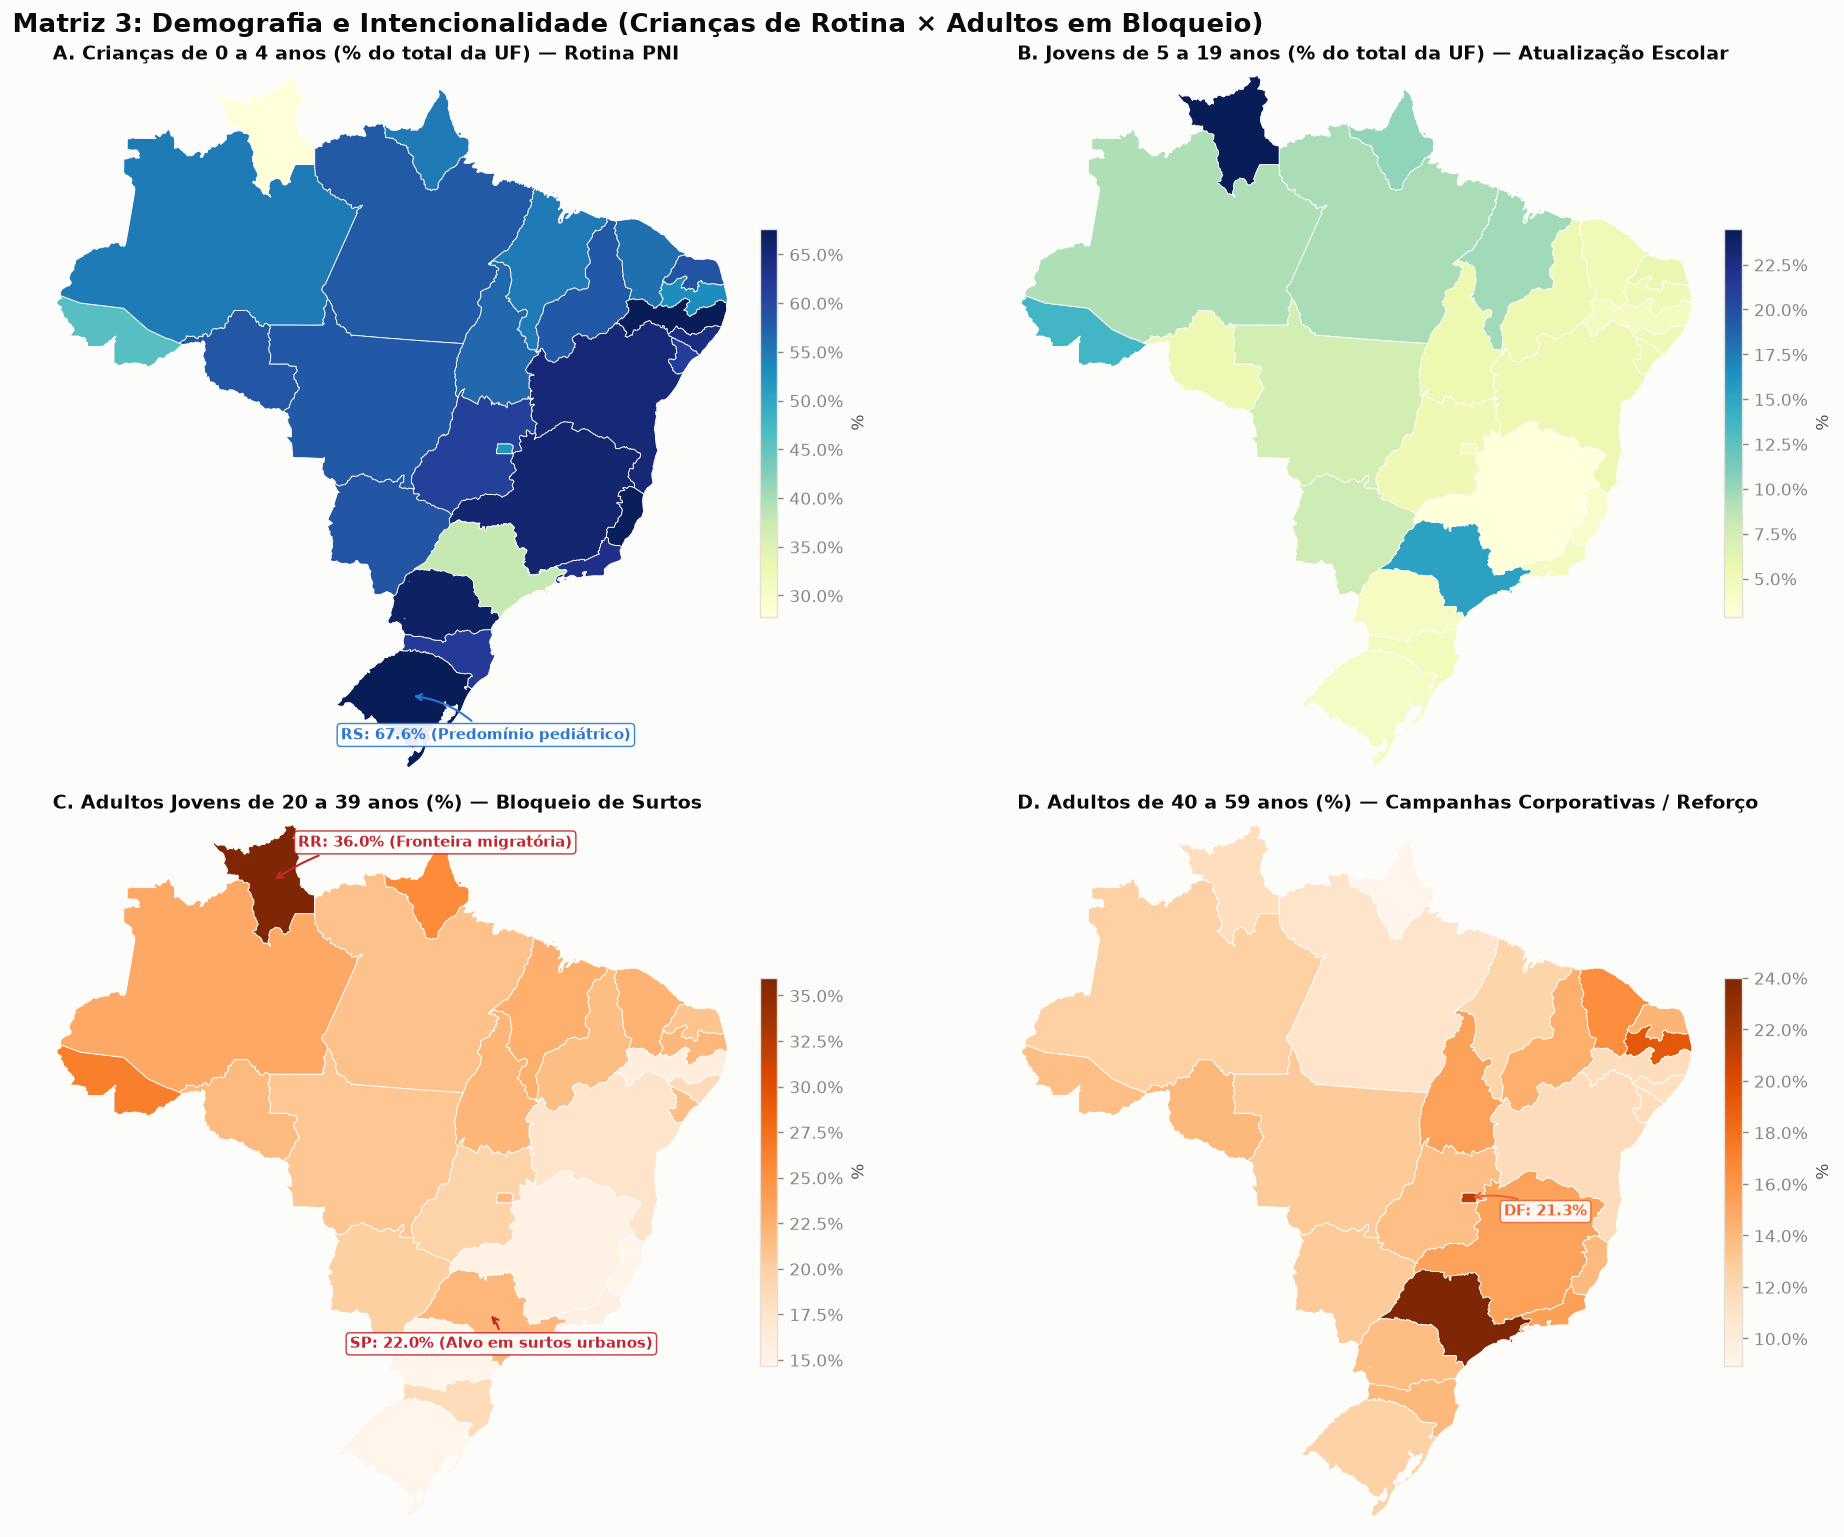

In [ ]:
# Agrupa doses por macrofaixa etária a partir de gold_perfil
tot_perfil = perfil[perfil["uf_paciente"].isin(sigla_uf)].groupby("uf_paciente")["doses"].sum()

def calcular_pct_faixas(faixas):
    sub = perfil[(perfil["uf_paciente"].isin(sigla_uf)) & (perfil["faixa_etaria"].isin(faixas))].groupby("uf_paciente")["doses"].sum()
    return (sub / tot_perfil * 100).fillna(0)

faixa_0_4 = calcular_pct_faixas(["<1", "1", "2-4"])
faixa_5_19 = calcular_pct_faixas(["5-9", "10-14", "15-19"])
faixa_20_39 = calcular_pct_faixas(["20-29", "30-39"])
faixa_40_59 = calcular_pct_faixas(["40-49", "50-59"])
adultos_20_59 = calcular_pct_faixas(["20-29", "30-39", "40-49", "50-59"])

fig, axes = plt.subplots(2, 2, figsize=(16, 12.5))

# Painel A: Crianças de 0 a 4 anos (Rotina Infantil)
norm_inf = mcolors.Normalize(vmin=faixa_0_4.min(), vmax=faixa_0_4.max())
coropletico(axes[0, 0], faixa_0_4.to_dict(), norm=norm_inf, cmap="YlGnBu",
            titulo="A. Crianças de 0 a 4 anos (% do total da UF) — Rotina PNI",
            rotulo="%", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})
anotacao_direcionada(axes[0, 0], "RS", f"RS: {faixa_0_4['RS']:.1f}% (Predomínio pediátrico)", xytext=(-40, -25), cor=BLUE)

# Painel B: 5 a 19 anos (Público Escolar)
norm_jov = mcolors.Normalize(vmin=faixa_5_19.min(), vmax=faixa_5_19.max())
coropletico(axes[0, 1], faixa_5_19.to_dict(), norm=norm_jov, cmap="YlGnBu",
            titulo="B. Jovens de 5 a 19 anos (% do total da UF) — Atualização Escolar",
            rotulo="%", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})

# Painel C: Adultos Jovens de 20 a 39 anos (Bloqueio Epidemiológico Ativo)
norm_ad1 = mcolors.Normalize(vmin=faixa_20_39.min(), vmax=faixa_20_39.max())
coropletico(axes[1, 0], faixa_20_39.to_dict(), norm=norm_ad1, cmap="Oranges",
            titulo="C. Adultos Jovens de 20 a 39 anos (%) — Bloqueio de Surtos",
            rotulo="%", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})
anotacao_direcionada(axes[1, 0], "SP", f"SP: {faixa_20_39['SP']:.1f}% (Alvo em surtos urbanos)", xytext=(-80, -20), cor=RED)
anotacao_direcionada(axes[1, 0], "RR", f"RR: {faixa_20_39['RR']:.1f}% (Fronteira migratória)", xytext=(15, 20), cor=RED)

# Painel D: Adultos de 40 a 59 anos
norm_ad2 = mcolors.Normalize(vmin=faixa_40_59.min(), vmax=faixa_40_59.max())
coropletico(axes[1, 1], faixa_40_59.to_dict(), norm=norm_ad2, cmap="Oranges",
            titulo="D. Adultos de 40 a 59 anos (%) — Campanhas Corporativas / Reforço",
            rotulo="%", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})
anotacao_direcionada(axes[1, 1], "DF", f"DF: {faixa_40_59['DF']:.1f}%", xytext=(20, -10), cor=ORANGE)

fig.suptitle("Matriz 3: Demografia e Intencionalidade (Crianças de Rotina × Adultos em Bloqueio)",
             x=0.06, ha="left", fontweight="bold", fontsize=15)
plt.tight_layout()
plt.show()

print("Estados com Maior Proporção de Vacinação em Adultos (20 a 59 anos):")
print(adultos_20_59.nlargest(5).round(1).map("{:.1f}%".format).to_string())
print("\nEstados com Menor Proporção de Adultos (Perfil Estritamente Pediátrico):")
print(adultos_20_59.nsmallest(5).round(1).map("{:.1f}%".format).to_string())

## 7. Matriz 4: Qualidade da Informação em Saúde (Oportunidade e Latência no RNDS)

### Constatação dos Dados
Na vigilância em saúde pública, o registro em tempo oportuno é crucial para a contenção de surtos.
Em `gold_atraso_registro.parquet`, o percentual de doses digitadas com **mais de 30 dias de atraso** (faixas `31-90 dias` e `> 90 dias`):
* **Excelente oportunidade e agilidade:** **Espírito Santo (apenas 1,5%)**, **Distrito Federal (7,7%)**, **Rio Grande do Norte (8,5%)** e **Piauí (8,7%)**.
* **Latência crítica de documentação:** **Roraima (22,0%)**, **Rio de Janeiro (17,4%)**, **Ceará (14,5%)** e **Maranhão (13,8%)**.

### Decisão de Visualização (Grade Semestral 2×2)
* **Estrutura:** 4 semestres consecutivos da série histórica (`2025-S1`, `2025-S2`, `2026-S1` e `2026-S2`).
* **Escala Compartilhada Sequencial (`Purples`):** Fixada entre `0%` e `35%` em todos os painéis.
* **Insight Visual:** Demonstra a evolução das políticas de informatização das Unidades Básicas de Saúde (UBS) e o impacto de ilhas de conectividade precária que atrasam o alerta epidemiológico.

UFs com Melhor Oportunidade de Registro (Menor Atraso Histórico):
uf_paciente
ES    1.5%
DF    7.7%
RN    8.5%
PI    8.7%

UFs com Maior Defasagem de Dados (Maior Atraso Histórico):
uf_paciente
RR    22.0%
RJ    17.4%
CE    14.5%
MA    13.8%


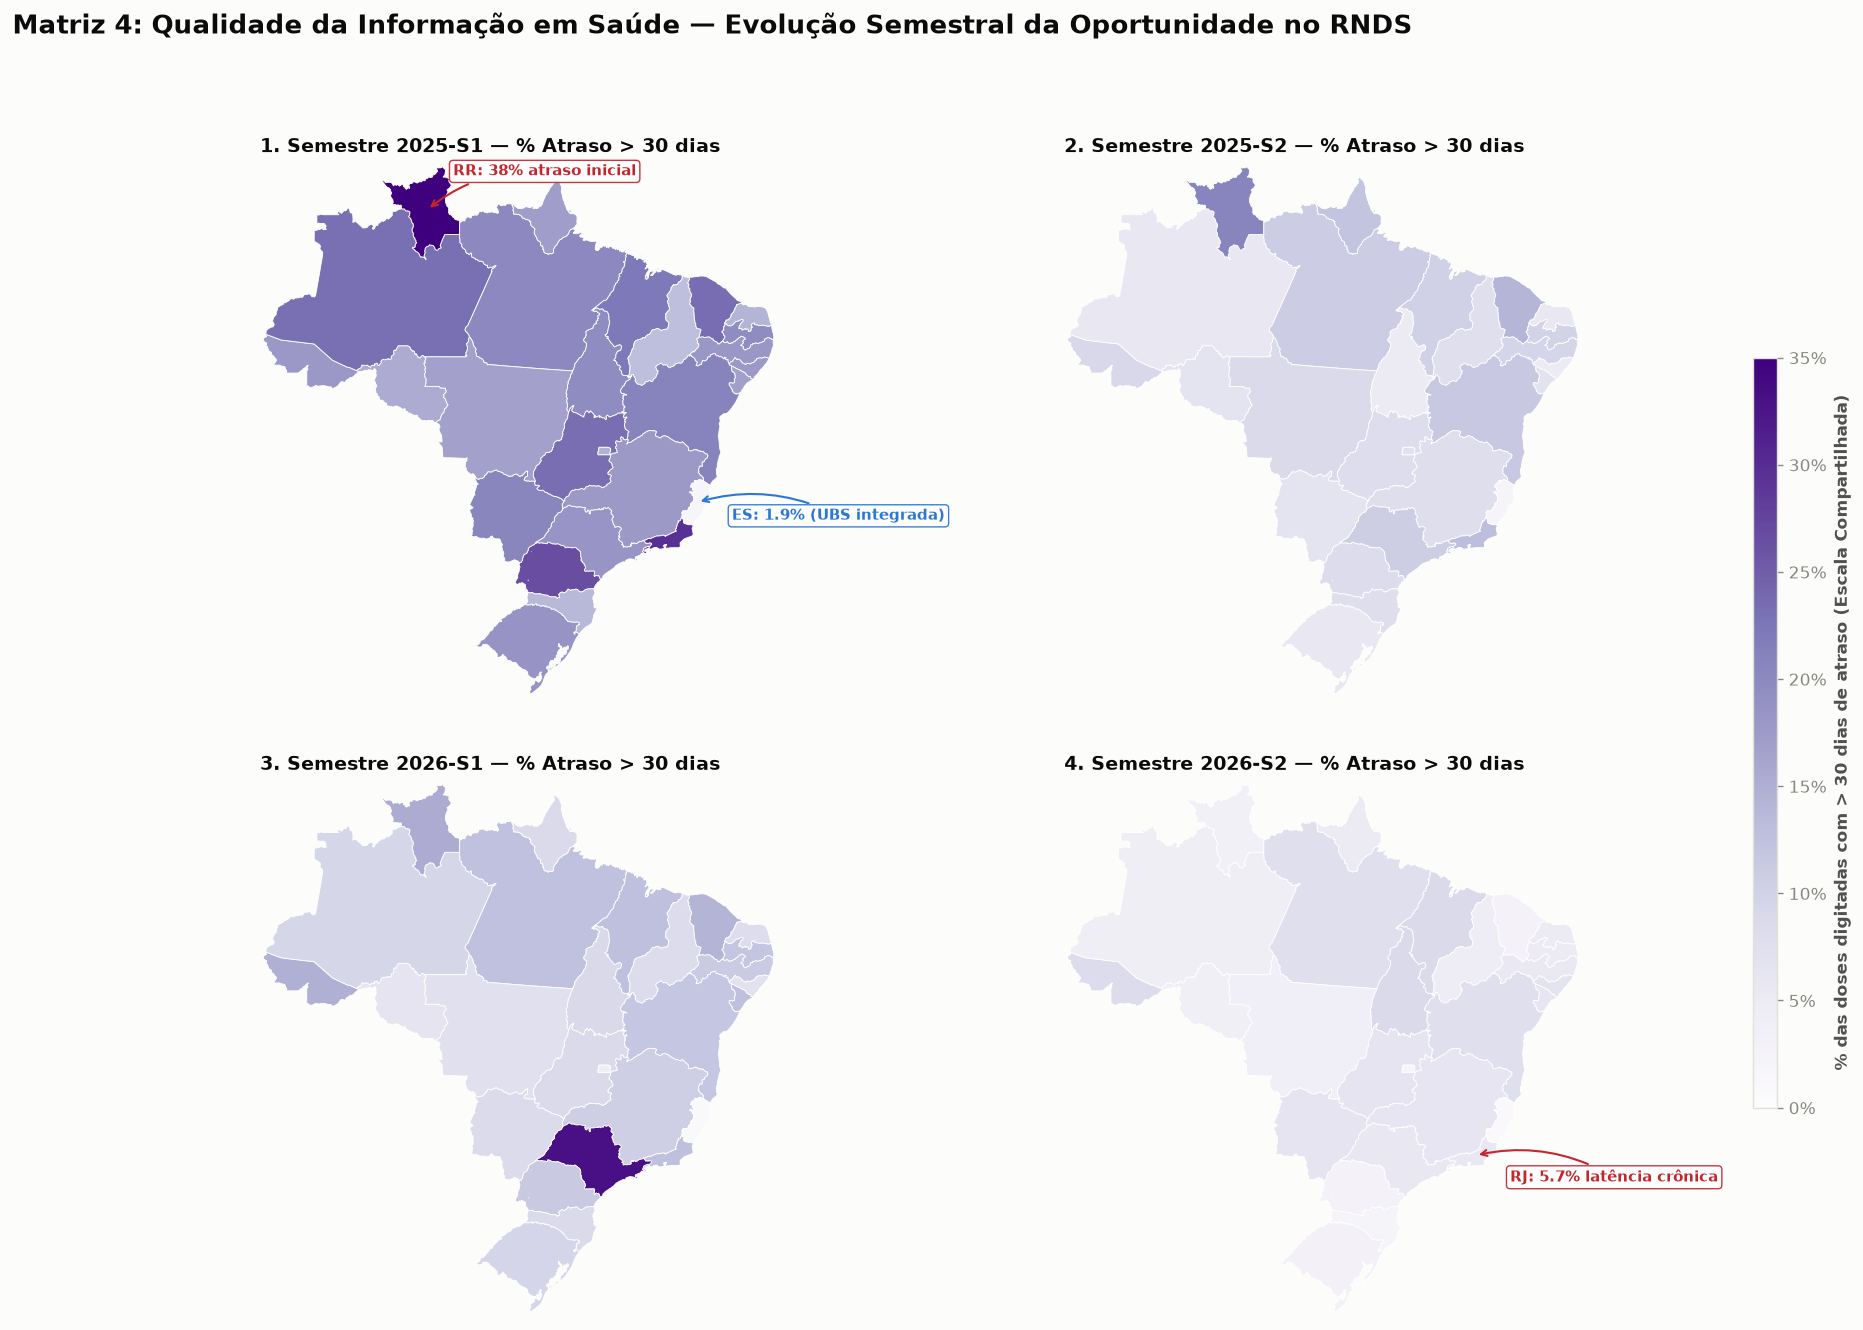

In [ ]:
# Agrupa atraso por semestre
atraso["ano"] = atraso["ano_mes"].str[:4].astype(int)
atraso["mes"] = atraso["ano_mes"].str[5:].astype(int)
atraso["semestre"] = atraso["ano"].astype(str) + "-S" + ((atraso["mes"] - 1) // 6 + 1).astype(str)

sem_tot = atraso[atraso["uf_paciente"].isin(sigla_uf)].groupby(["semestre", "uf_paciente"])["doses"].sum().unstack(0)
sem_tarde = atraso[(atraso["uf_paciente"].isin(sigla_uf)) & (atraso["faixa_atraso"].isin(["31-90 dias", "> 90 dias"]))].groupby(["semestre", "uf_paciente"])["doses"].sum().unstack(0)
pct_atraso_sem = (sem_tarde / sem_tot * 100).fillna(0)

semestres = sorted(pct_atraso_sem.columns)
norm_atraso = mcolors.Normalize(vmin=0, vmax=35)
cmap_atraso = plt.get_cmap("Purples")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

for i, sem in enumerate(semestres):
    ax = axes[i]
    coropletico(ax, pct_atraso_sem[sem].to_dict(), norm=norm_atraso, cmap=cmap_atraso, colorbar=False,
                titulo=f"{i+1}. Semestre {sem} — % Atraso > 30 dias")
    if sem == "2025-S1":
        anotacao_direcionada(ax, "RR", f"RR: {pct_atraso_sem.loc['RR', sem]:.0f}% atraso inicial", xytext=(15, 20), cor=RED)
        anotacao_direcionada(ax, "ES", f"ES: {pct_atraso_sem.loc['ES', sem]:.1f}% (UBS integrada)", xytext=(20, -10), cor=BLUE)
    elif sem == "2026-S2":
        anotacao_direcionada(ax, "RJ", f"RJ: {pct_atraso_sem.loc['RJ', sem]:.1f}% latência crônica", xytext=(20, -15), cor=RED)

# Barra de cores compartilhada
fig.subplots_adjust(right=0.91, hspace=0.15, wspace=0.05)
cax = fig.add_axes([0.93, 0.25, 0.012, 0.5])
sm_atr = plt.cm.ScalarMappable(cmap=cmap_atraso, norm=norm_atraso)
cb_atr = fig.colorbar(sm_atr, cax=cax)
cb_atr.set_label("% das doses digitadas com > 30 dias de atraso (Escala Compartilhada)", fontsize=10, fontweight="bold")
cb_atr.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:.0f}%"))

fig.suptitle("Matriz 4: Qualidade da Informação em Saúde — Evolução Semestral da Oportunidade no RNDS",
             x=0.06, ha="left", fontweight="bold", fontsize=15)
plt.show()

# Ranking consolidado geral de atraso
tot_atraso_uf = atraso[(atraso["uf_paciente"].isin(sigla_uf))].groupby("uf_paciente")["doses"].sum()
tot_tarde_uf = atraso[(atraso["uf_paciente"].isin(sigla_uf)) & (atraso["faixa_atraso"].isin(["31-90 dias", "> 90 dias"]))].groupby("uf_paciente")["doses"].sum()
pct_tarde_geral = (tot_tarde_uf / tot_atraso_uf * 100).dropna()

print("UFs com Melhor Oportunidade de Registro (Menor Atraso Histórico):")
print(pct_tarde_geral.nsmallest(4).round(1).map("{:.1f}%".format).to_string())
print("\nUFs com Maior Defasagem de Dados (Maior Atraso Histórico):")
print(pct_tarde_geral.nlargest(4).round(1).map("{:.1f}%".format).to_string())

## 8. Matriz 5: Insumos Farmacêuticos (Tríplice SCR vs Tetra viral SCRV)

### Constatação dos Dados
Na prevenção do sarampo, o PNI distribui duas formulações principais:
1. **Tríplice viral (SCR):** Sarampo, Caxumba e Rubéola.
2. **Tetra viral (SCRV):** Adiciona o componente contra Varicela (catapora), recomendada prioritariamente na 2ª dose (aos 15 meses).

Na tabela `gold_doses_uf_mes.parquet`, a **taxa de uso de SCRV sobre o total de vacinas com sarampo** varia intensamente:
* **Maiores proporções de SCRV:** **Amazonas (30,2%)**, **Rio Grande do Sul (29,3%)**, **Paraná (27,8%)** e **Rio de Janeiro (27,7%)**.
* **Menores proporções de SCRV:** **Pernambuco (8,6%)**, **Roraima (9,0%)** e **Minas Gerais (13,5%)**.

### Decisão de Visualização (Grade 1×2)
* **Painel A:** Mapa Coroplético do % de uso de Tetra Viral (SCRV).
* **Painel B:** Cartograma Hexagonal do mesmo indicador com anotações pontuais em cada hexágono.
* **Colorimetria:** Escala sequencial uniforme (`YlGn`) centrada na amplitude real dos insumos.

UFs com Maior Participação de Tetra Viral (SCRV):
uf_paciente
AM    30.2%
RS    29.3%
PR    27.8%
RJ    27.7%
SE    27.3%

UFs com Menor Participação de Tetra Viral (Predomínio de Tríplice Simples):
uf_paciente
PE     8.6%
RR     9.0%
MG    13.5%
PB    14.2%
SP    15.6%


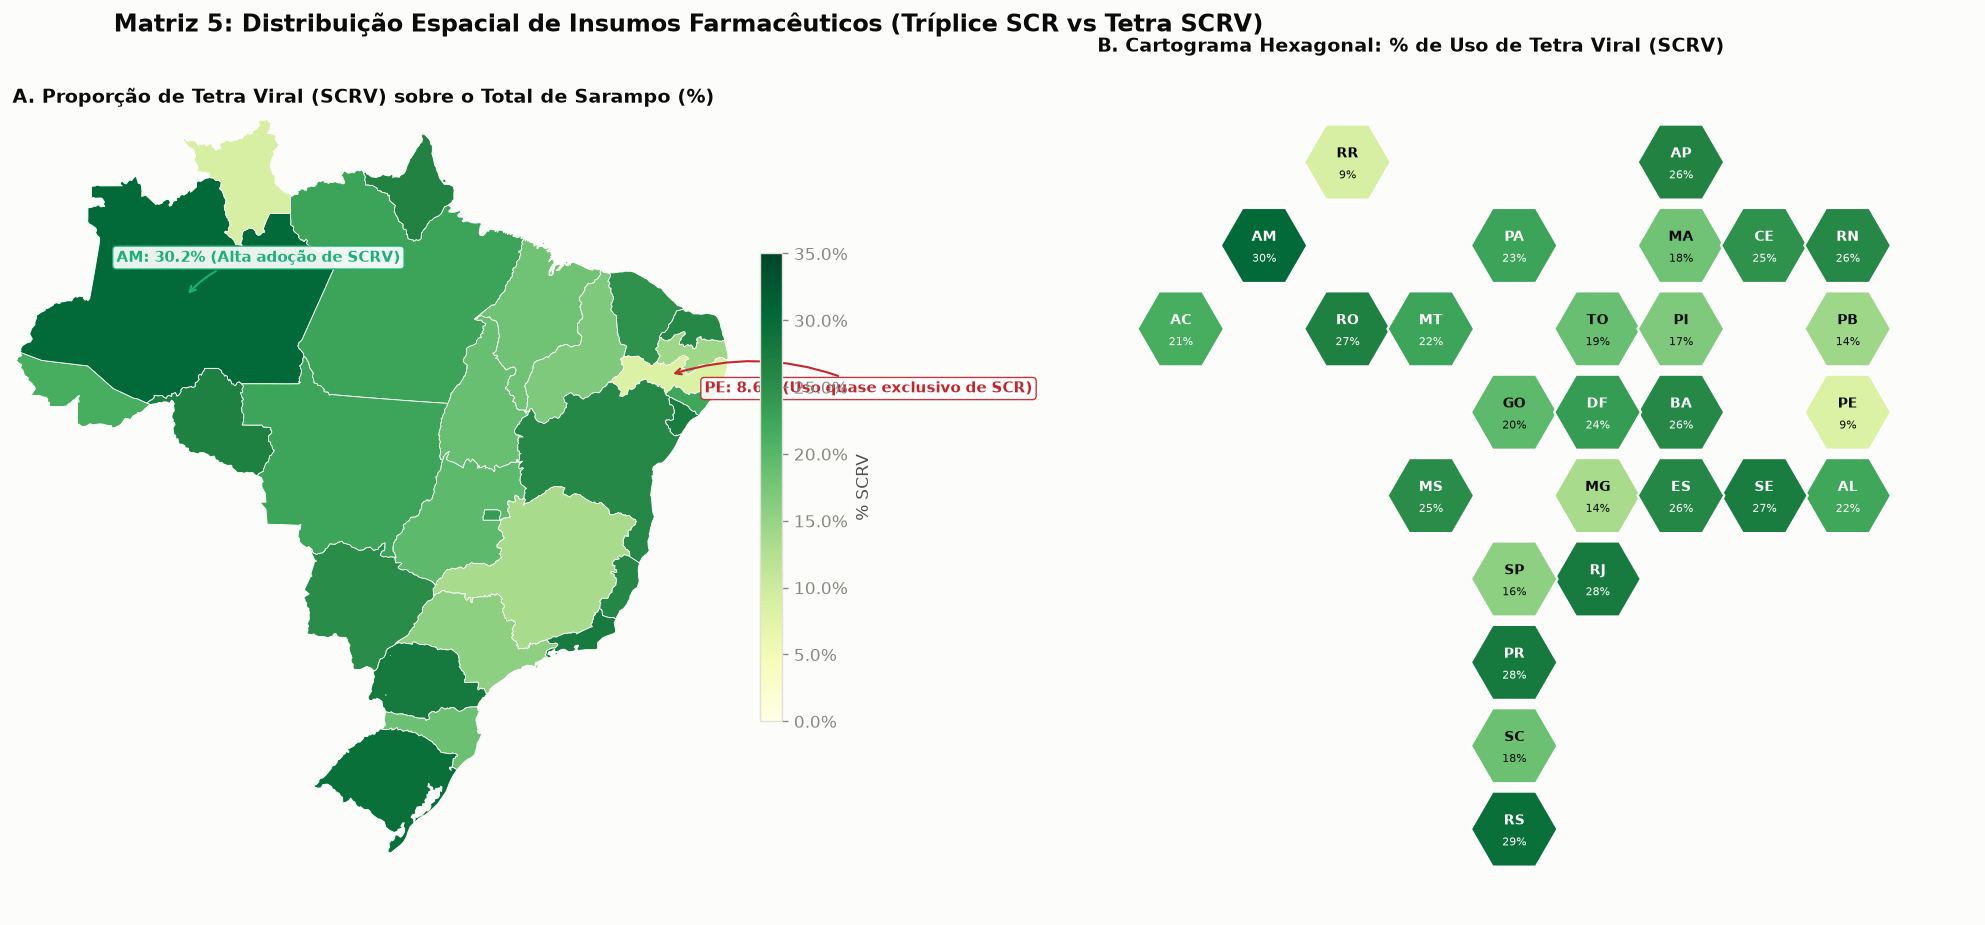

In [ ]:
# Agregação das formulações por UF
vac_uf = uf_mes[(uf_mes["uf_paciente"].isin(sigla_uf)) & (uf_mes["vacina_tipo"].isin(["Tríplice viral (SCR)", "Tetra viral (SCRV)"]))].groupby(["uf_paciente", "vacina_tipo"])["doses"].sum().unstack(fill_value=0)
pct_scrv = (vac_uf["Tetra viral (SCRV)"] / vac_uf.sum(axis=1) * 100).loc[lambda x: x.index.isin(sigla_uf)]

norm_scrv = mcolors.Normalize(vmin=0, vmax=35)
cmap_scrv = plt.get_cmap("YlGn")

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))

# Painel A: Mapa Coroplético
coropletico(axes[0], pct_scrv.to_dict(), norm=norm_scrv, cmap=cmap_scrv,
            titulo="A. Proporção de Tetra Viral (SCRV) sobre o Total de Sarampo (%)",
            rotulo="% SCRV", fmt="{:.1f}%", cbar_kw={"shrink": 0.55})
anotacao_direcionada(axes[0], "AM", f"AM: {pct_scrv['AM']:.1f}% (Alta adoção de SCRV)", xytext=(-40, 20), cor=GREEN)
anotacao_direcionada(axes[0], "PE", f"PE: {pct_scrv['PE']:.1f}% (Uso quase exclusivo de SCR)", xytext=(20, -10), cor=RED)

# Painel B: Cartograma Hexagonal
cartograma_hexagonal(axes[1], pct_scrv.to_dict(), norm=norm_scrv, cmap=cmap_scrv,
                     titulo="B. Cartograma Hexagonal: % de Uso de Tetra Viral (SCRV)",
                     fmt="{:.0f}%")

fig.suptitle("Matriz 5: Distribuição Espacial de Insumos Farmacêuticos (Tríplice SCR vs Tetra SCRV)",
             x=0.06, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

print("UFs com Maior Participação de Tetra Viral (SCRV):")
print(pct_scrv.nlargest(5).round(1).map("{:.1f}%".format).to_string())
print("\nUFs com Menor Participação de Tetra Viral (Predomínio de Tríplice Simples):")
print(pct_scrv.nsmallest(5).round(1).map("{:.1f}%".format).to_string())

## 9. Diretrizes Críticas e Roteiro de Apresentação (Disciplina Análise Visual de Dados)

Ao apresentar estes múltiplos cartográficos em banca ou seminário acadêmico, estruturamos os seguintes pontos de defesa técnica e metodológica:

### 1. Defesa Teórica da Escolha por Small Multiples (*Eyes Over Memory*)
* **Por que não utilizar um vídeo ou animação temporal?**  
  Demonstre à banca que animações forçam o espectador a depender de sua memória visual de curto prazo (*working memory limit*, Colin Ware). Na Matriz 1, a grade 2×4 expõe a série histórica completa de uma só vez, permitindo identificar que a megacampanha de agosto/2026 foi um fenômeno hiperconcentrado no Sudeste (SP +19,4x), sem qualquer esforço de retenção cognitiva.

### 2. A Rigidez Ética da Escala Compartilhada (*Fixed Colormap*)
* **O perigo de escalas automáticas/relativas:**  
  Mostre que em painéis múltiplos, permitir que cada faceta defina seu próprio `vmin`/`vmax` gera distorções científicas graves. Na Matriz 2 (D1 vs D2), a escala compartilhada evidencia visualmente a perda drástica de densidade de cor na segunda dose, comprovando o abandono vacinal antes mesmo de ler os números.

### 3. A Complementação com Cartogramas Hexagonais (*Mitigação do Area Bias*)
* **A paridade representativa dos dados:**  
  Ressalte que a Amazônia Legal (mais de 45% do mapa físico) atrai a atenção ocular involuntária. Ao apresentar o Cartograma Hexagonal lado a lado, devolve-se a visibilidade plena a unidades densas como DF, RJ e SE, neutralizando o viés geométrico e preservando a fidelidade analítica.

### 4. A Força das Anotações Direcionadas (*Directed Annotations*)
* Em apresentações de alta densidade visual, anotações pontuais atuam como âncoras cognitivas (*visual beacons*), conduzindo o olhar do avaliador imediatamente para os achados substantivos da pesquisa.

---

### Resumo Executivo das Matrizes Implementadas

```
+---------------------------------------------------------------------------------------------------------+
| MATRIZES DE SMALL MULTIPLES CARTOGRÁFICOS NA VACINAÇÃO CONTRA SARAMPO (MESTRADO UNESP)                  |
+-------------------+----------------------------+-----------------------+--------------------------------+
| Dimensão          | Métrica Analítica          | Configuração Visual   | Principal Insight Identificado |
+-------------------+----------------------------+-----------------------+--------------------------------+
| 1. Tempo          | Doses / 1.000 hab.         | Grade 2x4 Sequencial  | Megacampanha Ago/2026: SP salta|
|    (2025 - 2026)  | (Trimestres + Pico Ago/26) | Blues Compartilhada   | 19,4x vs 1,5x a 2x no Nordeste |
+-------------------+----------------------------+-----------------------+--------------------------------+
| 2. Completude     | D1 vs D2 por mil hab.      | Grade 2x2 Sequencial  | Abandono severo no Norte (RR   |
|    & Abandono     | e % coorte 1-4 anos 2+ dos | + Divergente (RdYlBu) | 38,3%) vs adesão em MG (59,6%) |
+-------------------+----------------------------+-----------------------+--------------------------------+
| 3. Demografia &   | % por 4 macrofaixas        | Grade 2x2 Sequencial  | SP (46%) e RR (47,5%) vacinam  |
|    Intenção       | (0-4, 5-19, 20-39, 40-59)  | YlGnBu e Oranges      | adultos em bloqueio/fronteira  |
+-------------------+----------------------------+-----------------------+--------------------------------+
| 4. Vigilância &   | % doses registradas com    | Grade 2x2 Semestral   | Latência de dados em RR (22%)  |
|    Qualidade      | atraso > 30 dias no RNDS   | Purples Compartilhada | e RJ (17%) vs ES ágil (1,5%)   |
+-------------------+----------------------------+-----------------------+--------------------------------+
| 5. Insumos        | % uso de Tetra viral (SCRV)| Grade 1x2 Coroplético | SCRV atinge 30% no AM e RS, mas|
|    Farmacêuticos  | sobre o total de sarampo   | + Cartograma Hexagonal| despenca para <9% em PE e RR   |
+-------------------+----------------------------+-----------------------+--------------------------------+
```